# **AI Basics for Engineers**

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# 📖 TABLE OF CONTENTS

- [Setup](#Setup)
- [What is Artificial Intelligence?](#What-is-Artificial-Intelligence?)
  - [Machine Learning](#Machine-Learning)
  - [Generative AI](#Generative-AI)
  - [Agentic AI](#Agentic-AI)
  - [AI vs Deterministic Code](#AI-vs-Deterministic-Code)
- [References](#References)

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# Setup

Before we jump in, let's quickly run the setup cell. It checks the environment (GPU, library versions) and sets random seeds for reproducibility — we want identical results on every run.

In [ ]:
# 🔧 Setup: Run this cell first!
# Environment check + random seeds for reproducibility

import sys
import time
import random
import numpy as np
import pandas as pd
import matplotlib as mpl
import torch
import torch.nn as nn

print(f"📦 Python       {sys.version.split()[0]}")
print(f"🔢 NumPy        {np.__version__}")
print(f"🐼 Pandas       {pd.__version__}")
print(f"📊 Matplotlib   {mpl.__version__}")
print(f"🔥 PyTorch      {torch.__version__}")

# GPU check (only needed for optional deep-feature experiments)
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"✅ GPU available: {torch.cuda.get_device_name(0)}")
    print(f"   Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    device = torch.device("cpu")
    print("⚠️ No GPU detected")

DEVICE_LABEL = "GPU" if device.type == "cuda" else "CPU"

# Random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"\n🎲 Random seed set to {SEED} (Python, NumPy, PyTorch)")

%matplotlib inline
%config InlineBackend.figure_format = 'jpeg'   # photos as JPEG, not PNG — ~10× smaller notebook
# Remove character limits for all columns of Pandas dataframes permanently in this session
pd.set_option('display.max_colwidth', None)

📦 Python       3.13.15
🔢 NumPy        2.1.3
🐼 Pandas       2.2.3
📊 Matplotlib   3.10.0
🔥 PyTorch      2.11.0+cpu
⚠️ No GPU detected

🎲 Random seed set to 42 (Python, NumPy, PyTorch)


![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# What is Artificial Intelligence?

Three overlapping ideas live under the AI umbrella. Knowing which one you are dealing with changes how you evaluate, test and trust it.

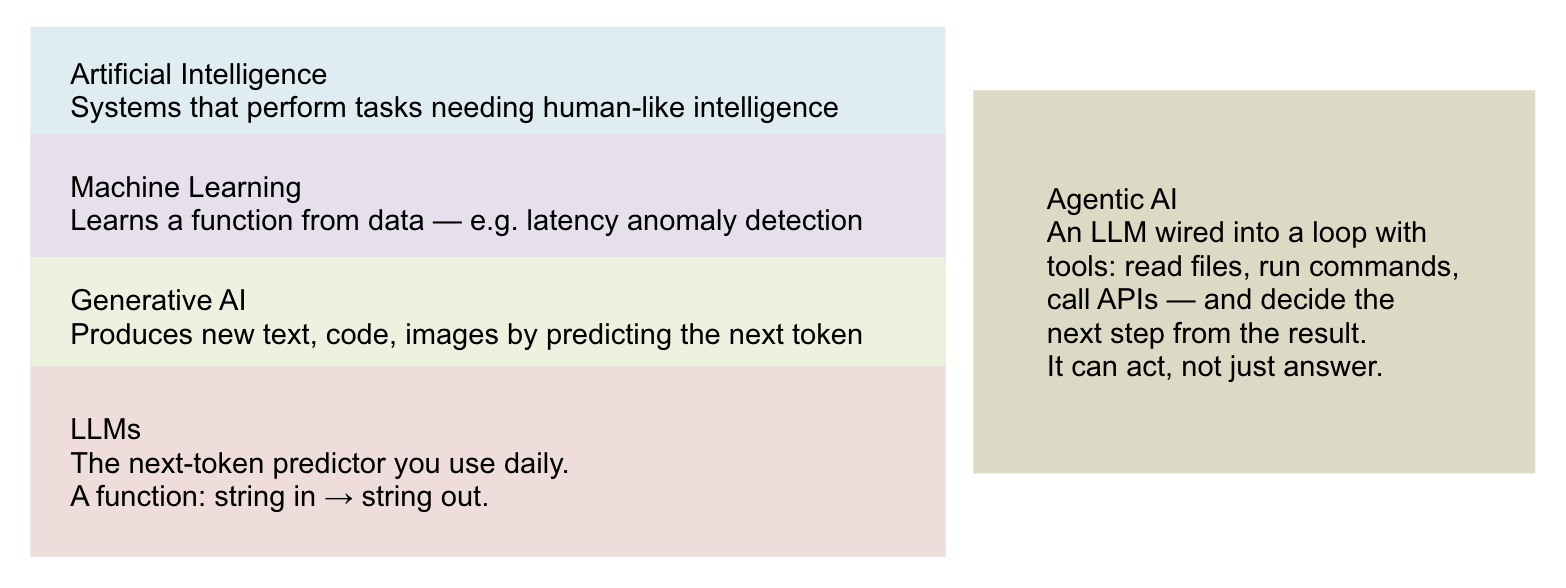

*The AI Landscape*

In [3]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/AI_Basics_for_Engineers-01.png", width=800))
display(Markdown("*The AI Landscape*"))

## Machine Learning

* Machine learning is the umbrella technique where a system learns a function from data instead of being explicitly programmed.
* You give it labeled examples (supervised), unlabeled examples (unsupervised), or a feedback signal (reinforcement), and the model fits parameters that minimize error on those examples.
* For your team, the most common encounter with classic ML is in observability and platform tooling; anomaly detection on log volume, latency, or error-rate metrics.
* A model learns the normal shape of a service's traffic and flags points that deviate. It does not understand causes; it just notices that something looks unlike the past.

## Generative AI

* Generative AI is the subset of ML that produces new artifacts: text, code, images, audio. Large language models (LLMs) are the variant most engineering teams interact with daily.
* They predict the next token over and over until a stopping condition is met, conditioned on whatever input you give them.
* Generative systems do not look things up. They generate. If the most statistically plausible next tokens describe a function or API that does not exist, you get a fluent confident description of nothing. That failure mode is hallucination, and we will return to it.
    * Strength: compressing patterns across enormous amounts of code, prose, and documentation into a single fluent interface.
    * Weakness: it cannot tell you that it does not know.

## Agentic AI

* An agent is an LLM wired into a loop with tools. It can read files, run commands, call APIs, and decide what to do next based on the results. The same underlying generative model is now allowed to act, not just respond.
* For engineers, agentic systems unlock real automation: an agent can open a branch, edit files, run tests, and open a pull request. The risk profile changes accordingly.
* The question shifts from "is the answer correct?" to "what is this allowed to do, and how do I know when it is done?".

## AI vs Deterministic Code

* Deterministic code, given the same input, returns the same output. You can write a unit test that asserts equality and the test will pass for years. AI systems are probabilistic.
* The same prompt can produce different completions, and the same input can produce subtly different judgments.
* The practical rule: if you can write down the rules, write the code. If you cannot (summarize this log, suggest a refactor, draft a migration), AI earns its place. Mixing the two is fine, but knowing which layer you are in matters.

| Property | Deterministic Code | AI System |
| :------- | :----------------- | :-------- |
| Behaviour on same input | Identical | May vary |
| Failure mode | Throws or returns wrong value | Often returns a confident, plausible wrong value |
| Test strategy | Unit tests, equality assertions | Evals, rubrics, sampling, human review |
| Right home | Anything you can specify precisely | Tasks where "good enough" beats "impossible to specify" |

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# References

- **Photon University: AI Basics for Engineers Course**

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)